In [21]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
import os
import random
import sys
sys.path.append("/home/dev/pose")

from pose.config import get_cfg_defaults

%matplotlib inline
import math
import torch

from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import InterpolationMode
from torchvision.transforms.v2 import ToPILImage
from torchvision.transforms.v2.functional import affine

from torchvision.utils import draw_bounding_boxes
from torchvision.utils import draw_keypoints

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

cfg = get_cfg_defaults()

connectivity = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
                [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
                [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]

In [23]:
from pose.data.dataset import CocoDataset

In [24]:
dataset = CocoDataset(anno_fname=cfg.DATA_TRAIN.ANNOTATION_FNAME,
                      image_dir=cfg.DATA_TRAIN.IMAGE_DIR,
                      nn_input_size=cfg.NN.INPUT_SIZE,
                      data_aug_cfg=cfg.DATA_TRAIN.DATA_AUG,
                      min_keypoints=cfg.DATA_COMMON.MIN_KEYPOINTS,
                      transform=None
                     )

2025-01-05 14:20:25.071 | INFO     | pose.data.dataset:_init_coco_info:120 - Keypoints idx2name: dict_items([(0, 'nose'), (1, 'L-eye'), (2, 'R-eye'), (3, 'L-ear'), (4, 'R-ear'), (5, 'L-shder'), (6, 'R-shder'), (7, 'L-elb'), (8, 'R-elb'), (9, 'L-wrst'), (10, 'R-wrst'), (11, 'L-hip'), (12, 'R-hip'), (13, 'L-knee'), (14, 'R-knee'), (15, 'L-ankl'), (16, 'R-ankl')])
2025-01-05 14:20:26.504 | INFO     | pose.data.dataset:__init__:49 - Annotation fname: /home/dev/data/coco/annotations/person_keypoints_train2017.json
2025-01-05 14:20:26.505 | INFO     | pose.data.dataset:__init__:52 - NN input size(height, width): [256, 192]
2025-01-05 14:20:26.506 | INFO     | pose.data.dataset:__init__:72 - Data augmentation: True
2025-01-05 14:20:26.963 | INFO     | pose.data.dataset:__init__:80 - Num images: 118,287
2025-01-05 14:20:26.964 | INFO     | pose.data.dataset:__init__:83 - Num raw annotations: 262,465
2025-01-05 14:20:32.075 | INFO     | pose.data.dataset:__init__:105 - skip crowd: 5,212
2025-01

2025-01-05 14:22:43.269 | DEBUG    | pose.data.dataset:_half_body_transform:206 - half body transform part: upper
2025-01-05 14:22:43.269 | DEBUG    | pose.data.dataset:_half_body_transform:212 - visible kps: 7
2025-01-05 14:22:43.270 | DEBUG    | pose.data.dataset:__getitem__:148 - the image is half-body transformed.
2025-01-05 14:22:43.270 | DEBUG    | pose.data.dataset:__getitem__:159 - rotate: 9.26, scale: 1.62
2025-01-05 14:22:43.272 | DEBUG    | pose.data.transforms:crop_and_resize_image:45 - original image size(c,h,w): torch.Size([3, 400, 600])
2025-01-05 14:22:43.273 | DEBUG    | pose.data.transforms:crop_and_resize_image:46 - original box size(h,w): 197, 101
2025-01-05 14:22:43.274 | DEBUG    | pose.data.transforms:crop_and_resize_image:47 - bbox center: [tensor(132, dtype=torch.int32), tensor(204, dtype=torch.int32)]
2025-01-05 14:22:43.275 | DEBUG    | pose.data.transforms:crop_and_resize_image:51 - bh=min(320.125, 536, 264)
2025-01-05 14:22:43.276 | DEBUG    | pose.data.tra

idx: 13015
Num keypoints: 7


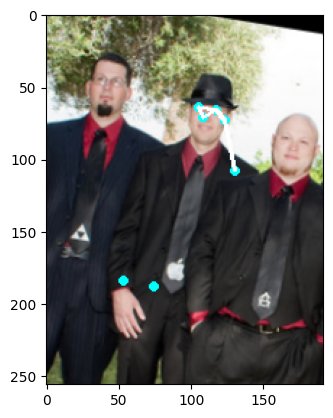

In [38]:
idx = random.randint(0, len(dataset)-1)
# idx = 91527
print(f"idx: {idx}")
nn_input, target_y, target_x, target_weight, extra_info = dataset[idx]
keypoints = extra_info["keypoints"]
image = extra_info["image"]

print(f"Num keypoints: {keypoints.num_visible()}")
kp = keypoints.get_kps(coord="xy").reshape(1,17,2)
vis = keypoints.get_vis().reshape(1,17)

image = draw_keypoints(image, kp, connectivity=connectivity, colors=COLOR_CYAN, radius=3, visibility=vis)
image = to_pil(image)
plt.imshow(image)
plt.show()

In [39]:
target_y.shape

torch.Size([17, 512])

In [40]:
kp_yx = keypoints.get_kps()
kp_yx

tensor([[ 71, 108],
        [ 66, 117],
        [ 64, 105],
        [ 73, 123],
        [ 71, 197],
        [108, 130],
        [108, 179],
        [  0,   0],
        [158, 167],
        [  0,   0],
        [184,  53],
        [196, 224],
        [188,  74],
        [  0,   0],
        [  0,   0],
        [  0,   0],
        [  0,   0]], dtype=torch.int32)

In [41]:
target_weight

tensor([[1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.]])

In [42]:
target_y.sum(axis=1)

tensor([1.0000, 1.0000, 1.0000, 1.0000, 0.0000, 1.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 1.0000, 0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000])

In [43]:
target_y[0]

tensor([0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+

In [44]:
buffer = 20
simcc_split_factor = 2
kp_y = int(kp_yx[0][0] * simcc_split_factor)

target_y[0, kp_y-buffer:kp_y+buffer]

tensor([0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        1.0930e-43, 7.9988e-38, 2.1464e-32, 2.1188e-27, 7.6946e-23, 1.0280e-18,
        5.0523e-15, 9.1347e-12, 6.0759e-09, 1.4867e-06, 1.3383e-04, 4.4318e-03,
        5.3991e-02, 2.4197e-01, 3.9894e-01, 2.4197e-01, 5.3991e-02, 4.4318e-03,
        1.3383e-04, 1.4867e-06, 6.0759e-09, 9.1347e-12, 5.0523e-15, 1.0280e-18,
        7.6946e-23, 2.1188e-27, 2.1464e-32, 7.9988e-38, 1.0930e-43, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00])

In [45]:
target_x.shape

torch.Size([17, 384])

In [46]:
target_x[0]

tensor([0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+

In [47]:
buffer = 20
simcc_split_factor = 2
kp_x = int(kp_yx[0][1] * simcc_split_factor)

target_x[0, kp_x-buffer:kp_x+buffer]

tensor([0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        1.0930e-43, 7.9988e-38, 2.1464e-32, 2.1188e-27, 7.6946e-23, 1.0280e-18,
        5.0523e-15, 9.1347e-12, 6.0759e-09, 1.4867e-06, 1.3383e-04, 4.4318e-03,
        5.3991e-02, 2.4197e-01, 3.9894e-01, 2.4197e-01, 5.3991e-02, 4.4318e-03,
        1.3383e-04, 1.4867e-06, 6.0759e-09, 9.1347e-12, 5.0523e-15, 1.0280e-18,
        7.6946e-23, 2.1188e-27, 2.1464e-32, 7.9988e-38, 1.0930e-43, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00])

index: 121590


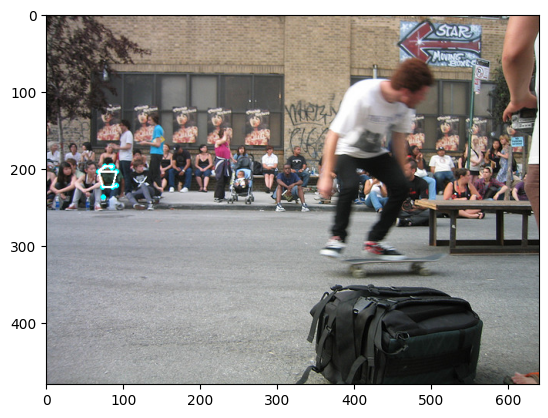

In [15]:
print(f"index: {idx}")
sample = dataset.get_sample(idx)
image_meta = dataset.get_image_meta(sample.image_id)
image_path = image_meta.fpath
image = read_image(image_path)
if image.shape[0] == 1:
    image = image.repeat(3, 1, 1)
keypoints = sample.keypoints
kp = keypoints.get_kps(coord="xy").reshape(1,17,2)
vis = keypoints.get_vis().reshape(1,17)
image = draw_keypoints(image, kp, connectivity=connectivity, colors=COLOR_CYAN, radius=3, visibility=vis)
image = to_pil(image)
plt.imshow(image)
plt.show()